# 03 — Anomalies, waste and their value in € and CO₂

**Goal:** turn the expected-consumption model of notebook 02 into information the building manager can act on:
*"It is Saturday, NW Plugs uses 3 kW more than expected — probably heaters left on. That costs €X and Y kg CO₂."*

We use **two signals**, because notebook 02 showed that one model cannot see everything:

| Signal | Question | How | Catches |
|---|---|---|---|
| 1. **Event** (model) | Is this hour far above what is normal *for this circuit, hour, day and weather*? | residual = actual − expected (LightGBM_forecast); alarm if above a robust threshold | sudden, unusual waste (something left on tonight) |
| 2. **Chronic off-hours waste** (rule) | How much energy is used above the standby level while the building is closed? | off-hours use − standby (10th percentile of night use) | waste that repeats every week (heaters on a timer), which a lag-based model learns as "normal" |

**Steps:** (1) expected use for every hour since 2020 → (2) choose the alarm threshold with a business rule → (3) test with
synthetic anomalies whether the detector finds forgotten loads → (4) events → (5) chronic waste → (6) € and CO₂ → (7) messages.

**No labels exist** (nobody wrote down when something was left on), so step 3 is our validation: we add a fake load
(e.g. a 1 kW heater) at night and check whether the detector finds it.

**Outputs** (inputs for the dashboard):
* `reports/anomaly_events.csv` — one row per event: circuit, start/end, excess kWh, €, kg CO₂, severity, message
* `reports/offhours_waste_daily.csv` — chronic waste per circuit per day
* `reports/savings_summary.csv` — potential savings per zone × device per year

All money, CO₂ and threshold parameters are in `params.yaml` (with sources), not in the code.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load, short, FOCUS, FIG, ROOT
from src.features import make_features, split_of
from src.models import make_lgb
from src.anomalies import (load_params, crossfit_expected, detect, events_fast, threshold_stats, hour_type,
                           offhours_waste, inject, value)

pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
REP = ROOT / "reports"
def save(fig, name): fig.savefig(FIG / f"anom_{name}.png", bbox_inches="tight")

P = load_params()
df = load()
df["split"] = split_of(df["timestamp_local"])
LGB = {k.replace(" ", "|", 1) + " W": v["forecast"] for k, v in json.load(open(REP / "model_params.json")).items()}
print("price all-in €/kWh:", P["price"]["all_in_eur_per_kwh"], "| CO2 g/kWh:", P["co2"]["g_per_kwh"])
print("event rules:", P["anomaly"])

price all-in €/kWh: 0.142 | CO2 g/kWh: {2020: 259, 2021: 259, 2022: 273, 2023: 260, 2025: 260}
event rules: {'k_mad': 4.0, 'min_event_hours': 2, 'merge_gap_hours': 1, 'min_event_kwh': 0.5, 'severity_kwh': [2, 10]}


## 1. Expected use for every hour since 2020

For a historical report we need an expected value for **every** hour, not only for the test months of notebook 02.
We use **cross-fitting**: Regime A is cut into calendar quarters, and each quarter is predicted by a model trained on all *other*
quarters. So no hour is predicted by a model that has seen it. 2025 is predicted by a model trained on all of 2020-23.

This is a *retrospective audit*. The honest forecast score (past → future only) is the one in notebook 02.
Model = LightGBM_forecast with the settings chosen in notebook 02 (`reports/model_params.json`).

In [2]:
expected = {}
for c in FOCUS:
    expected[c] = crossfit_expected(df, c, LGB[c])
htype = hour_type(df)
STATS = {c: threshold_stats(df[c] - expected[c], htype) for c in FOCUS}
print("Residual spread (scaled MAD, W) per hour type:")
pd.DataFrame({short(c): s["mad"] for c, s in STATS.items()}).T.round(0)

Residual spread (scaled MAD, W) per hour type:


,off-hours,working hours
NW Plugs & Sockets,166.0,239.0
SW Plugs & Sockets,36.0,63.0
SE Plugs & Sockets,30.0,45.0
NE Plugs & Sockets,5.0,5.0
NW Lighting,45.0,46.0
SW Lighting,0.0,107.0
SE Lighting,0.0,0.0
NW HVAC,19.0,15.0
SE HVAC,5.0,9.0


**→ Reading:** the "normal miss" of the model is much larger during working hours than off-hours, and much larger for NW Plugs than
for the other circuits. That is why the threshold is set **per circuit and per hour type**.

## 2. Choosing the alarm threshold — a business rule

An hour is flagged when `actual − expected > median + k × MAD` of its circuit and hour type. Flagged hours that follow each other
become one **event** (≥ 2 hours and ≥ 0.5 kWh above expected; smaller events are worth less than €0.07).

**How we choose k (the metric matches the decision):** a building manager stops reading alarms if there are too many.
We take, per circuit, the **smallest k that gives at most ~1 event per week** over the whole history.
A lower k finds more, but floods the manager. A higher k is calm, but misses more.

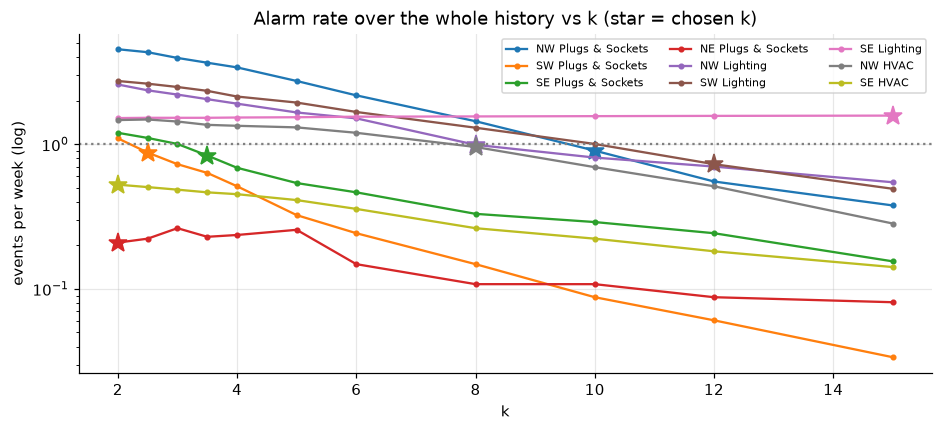

,NW Plugs & Sockets,SW Plugs & Sockets,SE Plugs & Sockets,NE Plugs & Sockets,NW Lighting,SW Lighting,SE Lighting,NW HVAC,SE HVAC
chosen k,10.0,2.5,3.5,2.0,8.0,12.0,15.0,8.0,2.0


In [3]:
K_GRID = [2, 2.5, 3, 3.5, 4, 5, 6, 8, 10, 12, 15]
weeks_hist = len(df) / 168

def n_events(c, k):
    H, _ = detect(df, c, expected[c], P, k=k, describe=False, stats=STATS[c])
    return events_fast(H, df["timestamp_local"], P)["event_id"].nunique()

rate = pd.DataFrame({short(c): {k: n_events(c, k) / weeks_hist for k in K_GRID} for c in FOCUS})
K_FINAL = {c: float(next((k for k in K_GRID if rate.loc[k, c] <= 1.0), K_GRID[-1])) for c in rate.columns}
json.dump(K_FINAL, open(REP / "anomaly_k.json", "w"), indent=2)

fig, ax = plt.subplots(figsize=(10, 4))
for c in rate.columns:
    line, = ax.plot(rate.index, rate[c], "-o", ms=3, label=c)
    ax.plot(K_FINAL[c], rate.loc[K_FINAL[c], c], "*", ms=13, color=line.get_color())
ax.axhline(1, color="grey", ls=":"); ax.set_yscale("log"); ax.set_xlabel("k"); ax.set_ylabel("events per week (log)")
ax.set_title("Alarm rate over the whole history vs k (star = chosen k)"); ax.legend(fontsize=7, ncol=3)
save(fig, "01_alarm_rate"); plt.show()
pd.Series(K_FINAL, name="chosen k").to_frame().T

**→ Finding:** The chosen k ranges from 2 (NE Plugs, SE HVAC: very regular circuits) to 10–15 (NW Plugs, SW/SE Lighting: circuits with large normal swings). Every circuit stays at about 1 event per week or less, except **SE Lighting**: in 2020-23 it was almost always 0, so its normal spread (MAD) is 0 and *any* use is unusual (1.6 events/week even at k = 15). Its alarms mean "this light is on, which is rare", not automatically "waste".

## 3. Does the detector find forgotten loads? (synthetic anomalies)

Set-up per circuit, using exactly the thresholds chosen above:
1. take the validation + test period (Sep 2022 – Feb 2023; the model below is trained on Jun 2020 – Aug 2022 only);
2. inject 40 fake loads of 3–12 hours, only in off-hours: 1 kW for plugs (one heater), 300 W for lighting / HVAC;
3. predict the injected series (the fake load also enters the lags, as it would in reality) and run the detector;
4. **recall** = share of fake loads found; **other events / week** = events that do not touch a fake load
   (real anomalies *or* false alarms — we cannot tell which, so the precision shown is a lower bound).

In [4]:
mask_eval = df["split"].isin(["val", "test"])
weeks_eval = mask_eval.sum() / 168

def synthetic_run(target, extra=None):
    Pt = json.loads(json.dumps(P))
    if extra is not None:
        Pt["synthetic_test"]["extra_w"] = {kk: extra for kk in Pt["synthetic_test"]["extra_w"]}
    d2, inj = inject(df, target, mask_eval, Pt)
    X = make_features(d2, target, "forecast")
    tr = (df["split"] == "train") & df[target].notna()
    model = make_lgb(**LGB[target]).fit(X[tr], df.loc[tr, target])
    sub, injs = d2[mask_eval], inj[mask_eval]
    H, _ = detect(sub, target, pd.Series(model.predict(X[mask_eval]), index=sub.index), P,
                  k=K_FINAL[short(target)], describe=False, stats=STATS[target])
    ev = events_fast(H, sub["timestamp_local"], P)
    hit = pd.Series(False, index=sub.index); hit[ev["row"].values] = True
    starts = injs & ~injs.shift(fill_value=False)
    block = starts.cumsum().where(injs)
    other = sum(1 for _, g in ev.groupby("event_id") if not injs[g["row"].values].any())
    return {"circuit": short(target), "extra_W": extra or next(v for k, v in P["synthetic_test"]["extra_w"].items() if k in target),
            "k": K_FINAL[short(target)], "recall": block[hit & injs].nunique() / starts.sum(),
            "other_events_per_week": other / weeks_eval, "precision_lower_bound": (hit & injs).sum() / max(hit.sum(), 1)}

synth = pd.DataFrame([synthetic_run(c) for c in FOCUS]).set_index("circuit")
synth.round(2)

,extra_W,k,recall,other_events_per_week,precision_lower_bound
circuit,,,,,
NW Plugs & Sockets,1000,10.0,0.32,1.93,0.17
SW Plugs & Sockets,1000,2.5,1.00,0.97,0.42
SE Plugs & Sockets,1000,3.5,1.00,1.28,0.72
NE Plugs & Sockets,1000,2.0,0.98,0.27,0.53
NW Lighting,300,8.0,0.10,0.23,0.44
SW Lighting,300,12.0,1.00,0.77,0.72
SE Lighting,300,15.0,0.98,5.07,0.27
NW HVAC,300,8.0,1.00,0.35,0.77
SE HVAC,300,2.0,1.00,0.35,0.48


**→ Finding:** With the production thresholds, the detector finds **98–100 % of the injected loads on 7 of the 9 circuits**. The two exceptions are the noisiest circuits: **NW Plugs** finds only 32 % of 1 kW loads and **NW Lighting** 10 % of 300 W loads, because their normal hour-to-hour swings are larger than one forgotten device. "Other events" are higher here than over the whole history (e.g. 1.9/week for NW Plugs) because the test months are winter months, the most variable season. SE Lighting has 5 other events/week in this period: any use of that light is flagged (see above).

### How large must a forgotten load be before we see it? (NW Plugs & Sockets)

In [5]:
T = "NW|Plugs & Sockets W"
size_tab = pd.DataFrame([synthetic_run(T, extra=s) for s in [1000, 2000, 3000, 5000, 8000]]).set_index("extra_W")
size_tab[["k", "recall", "other_events_per_week"]].round(2)

,k,recall,other_events_per_week
extra_W,,,
1000,10.0,0.32,1.93
2000,10.0,0.85,1.86
3000,10.0,0.92,1.82
5000,10.0,0.98,1.78
8000,10.0,0.98,1.66


**→ Finding:** On NW Plugs a single forgotten heater (1 kW) is usually **not** visible as an event, but **2 kW is found 85 % of the time, 3 kW 92 % and 5 kW 98 %**. So the event signal catches *several* heaters or a large device left on. Smaller, repeating loads are what signal 2 (chronic off-hours waste, section 5) is for.

*We also tried judging whole nights / weekend days instead of single hours (sum of residuals per off-hours block).
It did **not** improve recall for NW Plugs (9–17 % for a 1 kW load): the residuals are strongly correlated from hour to hour,
so the noise does not cancel out.*

## 4. Signal 1 — anomaly events over the whole history

In [6]:
events, hours = [], {}
for c in FOCUS:
    H, E = detect(df, c, expected[c], P, k=K_FINAL[short(c)], stats=STATS[c])
    hours[c] = H
    events.append(E)
events = pd.concat(events, ignore_index=True).sort_values("excess_kWh", ascending=False)
events.to_csv(REP / "anomaly_events.csv", index=False)
summ = events.groupby("circuit").agg(events=("excess_kWh", "size"), per_week=("excess_kWh", lambda s: s.size / weeks_hist),
                                     excess_kWh=("excess_kWh", "sum"), off_hours_share=("share_off_hours", "mean"),
                                     high=("severity", lambda s: (s == "high").sum()))
summ.sort_values("excess_kWh", ascending=False).round(2)

,events,per_week,excess_kWh,off_hours_share,high
circuit,,,,,
NW Plugs & Sockets,134,0.90,2026.90,0.57,60
SE Lighting,234,1.58,803.50,0.08,7
NW Lighting,147,0.99,679.10,0.57,8
SW Lighting,108,0.73,582.39,0.44,13
SE Plugs & Sockets,124,0.84,298.53,0.30,3
NW HVAC,142,0.96,231.50,0.52,0
SW Plugs & Sockets,130,0.88,198.00,0.31,0
SE HVAC,78,0.53,100.15,0.66,0
NE Plugs & Sockets,31,0.21,94.06,0.48,3


### Manual check of the top 10 events
No labels exist, so we look at the largest events one by one and ask: *does this look like waste?*

In [7]:
top = events.head(10)[["circuit", "start", "end", "hours", "day_type", "actual_kWh", "expected_kWh", "excess_kWh",
                       "eur_all_in", "kg_co2", "severity", "message"]]
top.round(1)

,circuit,start,end,hours,day_type,actual_kWh,expected_kWh,excess_kWh,eur_all_in,kg_co2,severity,message
113,NW Plugs & Sockets,2023-01-04 10:00:00,2023-01-06 07:00:00,44,break (Xmas/Easter/Aug),250.1,86.9,163.2,23.2,42.4,high,Plug load higher than expected while the building is closed on a cold day: possibly electric heaters left on.
59,NW Plugs & Sockets,2022-02-25 15:00:00,2022-02-26 19:00:00,27,weekend,137.1,40.6,96.4,13.7,26.3,high,Plug load higher than expected while the building is closed on a cold day: possibly electric heaters left on.
26,NW Plugs & Sockets,2021-11-18 16:00:00,2021-11-19 08:00:00,16,working day,82.8,22.7,60.1,8.5,15.6,high,Plug load higher than expected during working hours on a cold day: possibly electric heaters left on.
101,NW Plugs & Sockets,2022-11-24 15:00:00,2022-11-25 07:00:00,16,working day,73.0,18.7,54.2,7.7,14.8,high,Plug load higher than expected during working hours: devices left on?
68,NW Plugs & Sockets,2022-03-11 17:00:00,2022-03-12 07:00:00,14,weekend,67.4,18.4,48.9,7.0,13.4,high,Plug load higher than expected while the building is closed on a cold day: possibly electric heaters left on. Indoor...
287,SE Plugs & Sockets,2021-05-23 08:00:00,2021-05-30 08:00:00,166,working day,112.4,64.4,48.0,6.8,12.4,high,Plug load higher than expected while the building is closed: devices left on?
67,NW Plugs & Sockets,2022-03-09 14:00:00,2022-03-10 07:00:00,16,working day,79.2,32.1,47.1,6.7,12.9,high,Plug load higher than expected during working hours on a cold day: possibly electric heaters left on.
74,NW Plugs & Sockets,2022-04-04 08:00:00,2022-04-04 19:00:00,11,working day,59.6,15.6,44.0,6.2,12.0,high,Plug load higher than expected during working hours on a cold day: possibly electric heaters left on.
112,NW Plugs & Sockets,2023-01-02 07:00:00,2023-01-02 16:00:00,9,break (Xmas/Easter/Aug),61.9,19.5,42.4,6.0,11.0,high,Plug load higher than expected while the building is closed on a cold day: possibly electric heaters left on.
98,NW Plugs & Sockets,2022-11-21 15:00:00,2022-11-22 07:00:00,15,working day,64.6,22.6,42.1,6.0,11.5,high,Plug load higher than expected while the building is closed on a cold day: possibly electric heaters left on.


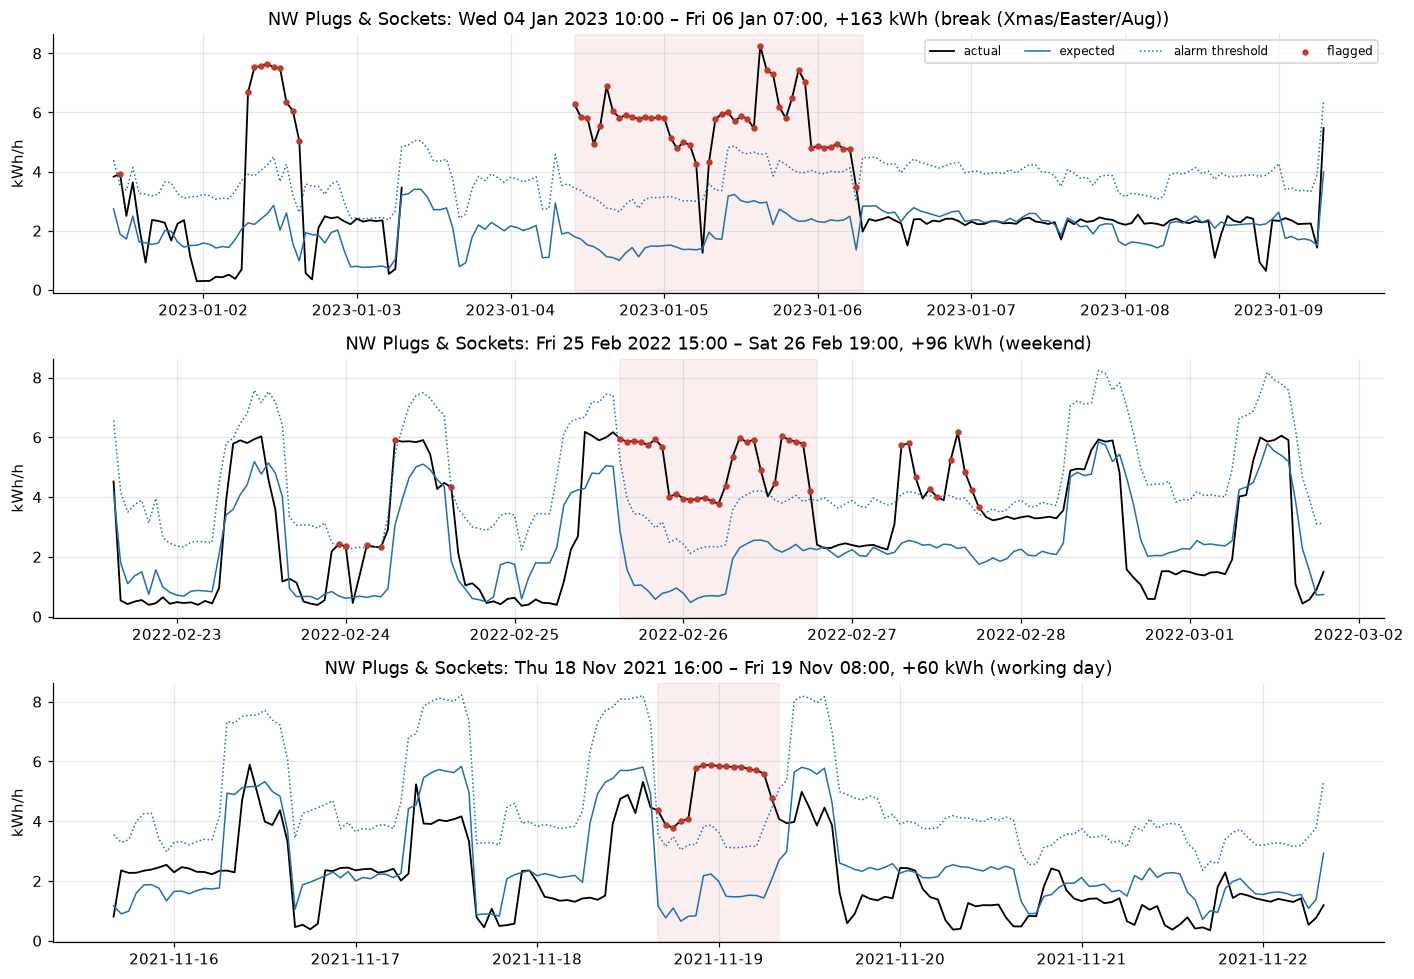

In [8]:
def plot_event(ax, e, days=3):
    c = next(x for x in FOCUS if short(x) == e["circuit"])
    H = hours[c]; ts = df["timestamp_local"]
    w = (ts >= e["start"] - pd.Timedelta(days=days)) & (ts <= e["end"] + pd.Timedelta(days=days))
    t = ts[w]
    ax.plot(t, H.loc[w, "actual"] / 1000, color="black", lw=1.2, label="actual")
    ax.plot(t, H.loc[w, "expected"] / 1000, color="#1f6fb2", lw=1, label="expected")
    ax.plot(t, (H.loc[w, "expected"] + H.loc[w, "threshold"]) / 1000, color="#1f6fb2", ls=":", lw=1, label="alarm threshold")
    fl = w & H["flag_model"].fillna(False)
    ax.scatter(ts[fl], H.loc[fl, "actual"] / 1000, color="#c0392b", s=10, zorder=5, label="flagged")
    ax.axvspan(e["start"], e["end"], color="#c0392b", alpha=0.08)
    ax.set_title(f"{e['circuit']}: {e['start']:%a %d %b %Y %H:%M} – {e['end']:%a %d %b %H:%M}, +{e['excess_kWh']:.0f} kWh ({e['day_type']})")
    ax.set_ylabel("kWh/h")

fig, axes = plt.subplots(3, 1, figsize=(13, 9))
for ax, (_, e) in zip(axes, events.head(3).iterrows()):
    plot_event(ax, e)
axes[0].legend(ncol=4, fontsize=8)
fig.tight_layout(); save(fig, "02_top_events"); plt.show()

**→ Finding:** The largest events look like **real waste**. In the three plotted NW Plugs events the use stays **flat and high through the night** (≈ 4–6 kWh/h at 03:00, where the expected value is ≈ 1–2). Normal work would drop off in the evening; heaters left on do not. Examples: Thursday night 18–19 Nov 2021 (+60 kWh), Friday evening to Saturday evening 25–26 Feb 2022 (+96 kWh), and 4–6 Jan 2023 (+163 kWh). The last one falls in the assumed Christmas break: part of it may be people working (2 January also shows a working-day pattern), but the flat night-time level points to heaters running day and night. The messages make the right guess ("possibly electric heaters left on"). One SE Plugs event lasts a whole week (May 2021, +48 kWh): a device that stayed on.

## 5. Signal 2 — chronic off-hours waste
Standby level = 10th percentile of night-time use in the training period ("the lowest level the circuit reaches when nobody is there").
Everything above standby during nights, weekends, holidays and breaks counts as *potentially avoidable*.

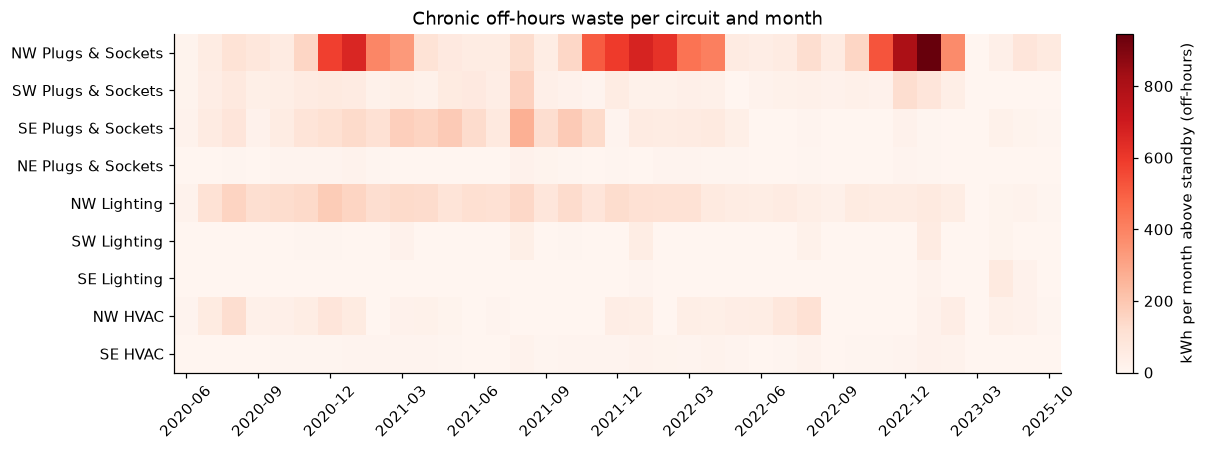

,NW Plugs & Sockets,SW Plugs & Sockets,SE Plugs & Sockets,NE Plugs & Sockets,NW Lighting,SW Lighting,SE Lighting,NW HVAC,SE HVAC
standby W,415.0,186.0,97.0,184.0,1.0,0.0,0.0,34.0,44.0


In [9]:
train = df["split"] == "train"
waste = {c: offhours_waste(df, c, P, train) for c in FOCUS}
daily = pd.concat({short(c): w.groupby(df["date_local"]).sum(numeric_only=True).drop(columns="standby_W") for c, w in waste.items()},
                  names=["circuit", "date"]).reset_index()
daily.to_csv(REP / "offhours_waste_daily.csv", index=False)

monthly = pd.DataFrame({short(c): w["excess_kWh"].groupby(df["timestamp_local"].dt.to_period("M")).sum() for c, w in waste.items()})
fig, ax = plt.subplots(figsize=(13, 4))
im = ax.imshow(monthly.T, aspect="auto", cmap="Reds")
ax.set_yticks(range(monthly.shape[1]), monthly.columns); ax.grid(False)
xt = list(range(0, len(monthly), 3)); ax.set_xticks(xt, [str(monthly.index[i]) for i in xt], rotation=45)
fig.colorbar(im, ax=ax, label="kWh per month above standby (off-hours)")
ax.set_title("Chronic off-hours waste per circuit and month"); save(fig, "03_chronic_heatmap"); plt.show()
pd.Series({short(c): w["standby_W"].iat[0] for c, w in waste.items()}, name="standby W").round(0).to_frame().T

**→ Finding:** Chronic waste is dominated by **NW Plugs in the heating season** (400–900 kWh per month above standby from November to March) — the heaters of notebook 01. **NW Lighting** adds a steady ≈ 60–150 kWh every month: the night light that is on every night from 22:00 to 07:00. **SE Plugs** was high in 2021 and **dropped sharply from 2022 on**: something changed in that zone (equipment removed or switched off), which shows the savings are achievable. Standby levels: NW Plugs ≈ 415 W, SW/NE Plugs ≈ 185 W, SE Plugs ≈ 100 W (always-on equipment such as fridges, routers, printers), lighting ≈ 0.

## 6. What is it worth? € and CO₂ per year

* **Potential savings = chronic off-hours waste** (all off-hours use above standby). Event excess during off-hours is already inside this number.
* **Events during working hours are shown, but not counted as savings**: part of that use is legitimate (somebody is working);
  they are a list "to investigate", not money on the table.
* € **OMIE** = hourly wholesale energy price only (no network charges, no taxes) → the real cost at that hour is higher.
  € **all-in** = fixed 0.142 €/kWh incl. charges and taxes (Eurostat, as in the Sprint 2 report). Note: in 2022 (energy crisis)
  the wholesale price alone was *above* 0.142 €/kWh, so for 2022 the all-in figure underestimates the cost.
* CO₂ with the CNMC grid-mix factor per year (`params.yaml`, to be confirmed by the KAN-134 owner).

We show the two complete calendar years in the data, **2021 and 2022**.

In [10]:
rows = []
for c in FOCUS:
    w, H = waste[c], hours[c]
    ev_rows = events_fast(H, df["timestamp_local"], P)["row"]
    ev_work = pd.Series(0.0, index=df.index)
    sel = pd.Index(ev_rows)[~df.loc[ev_rows, "is_off_hours"].values]
    ev_work[sel] = (H.loc[sel, "resid"].clip(lower=0) / 1000).values
    for y in [2021, 2022]:
        m = df["timestamp_local"].dt.year == y
        rows.append({"year": y, "zone": c.split("|")[0], "device": c.split("|")[1].removesuffix(" W"),
                     "potential_kWh": w.loc[m, "excess_kWh"].sum(), "eur_omie": w.loc[m, "eur_omie"].sum(),
                     "eur_all_in": w.loc[m, "eur_all_in"].sum(), "kg_co2": w.loc[m, "kg_co2"].sum(),
                     "to_investigate_workhours_kWh": ev_work[m].sum(), "total_use_kWh": df.loc[m, c].sum() / 1000})
sav = pd.DataFrame(rows)
sav["share_of_use_%"] = 100 * sav["potential_kWh"] / sav["total_use_kWh"]
sav.to_csv(REP / "savings_summary.csv", index=False)
sav.round(1)

,year,zone,device,potential_kWh,eur_omie,eur_all_in,kg_co2,to_investigate_workhours_kWh,total_use_kWh,share_of_use_%
0,2021,NW,Plugs & Sockets,3068.7,337.5,435.8,794.8,205.0,9455.5,32.5
1,2022,NW,Plugs & Sockets,3947.5,662.3,560.5,1077.7,474.8,12335.2,32.0
2,2021,SW,Plugs & Sockets,572.8,57.7,81.3,148.4,39.9,2664.5,21.5
3,2022,SW,Plugs & Sockets,370.5,49.8,52.6,101.2,51.4,2458.9,15.1
4,2021,SE,Plugs & Sockets,1677.4,161.3,238.2,434.5,84.9,3822.5,43.9
5,2022,SE,Plugs & Sockets,281.3,56.9,39.9,76.8,64.7,1385.5,20.3
6,2021,NE,Plugs & Sockets,79.4,8.1,11.3,20.6,16.0,1591.0,5.0
7,2022,NE,Plugs & Sockets,55.6,9.2,7.9,15.2,15.7,1476.5,3.8
8,2021,NW,Lighting,1440.2,141.7,204.5,373.0,102.7,2008.1,71.7
9,2022,NW,Lighting,757.0,137.2,107.5,206.7,25.3,1142.8,66.2


In [11]:
tot = sav.groupby("year")[["potential_kWh", "eur_omie", "eur_all_in", "kg_co2", "total_use_kWh"]].sum()
tot["t_co2"] = tot.pop("kg_co2") / 1000
tot["share_of_focus_use_%"] = 100 * tot["potential_kWh"] / tot["total_use_kWh"]
print("Storey 1, 9 focus circuits — potential savings per year")
tot.round(1)

Storey 1, 9 focus circuits — potential savings per year


,potential_kWh,eur_omie,eur_all_in,total_use_kWh,t_co2,share_of_focus_use_%
year,,,,,,
2021,7182.2,741.1,1019.9,22303.8,1.9,32.2
2022,6004.3,1013.4,852.6,22589.7,1.6,26.6


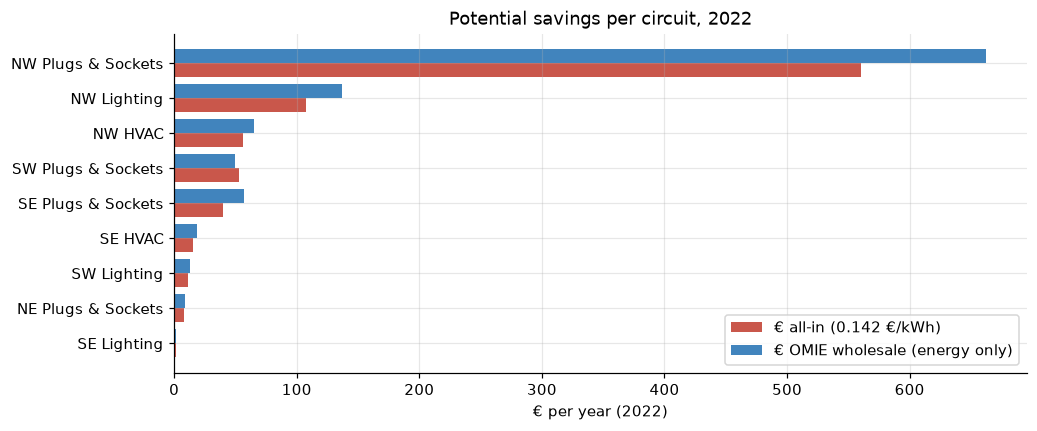

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
s22 = sav[sav.year == 2022].assign(label=lambda d: d.zone + " " + d.device).set_index("label").sort_values("eur_all_in")
y = np.arange(len(s22))
ax.barh(y - 0.2, s22["eur_all_in"], height=0.4, color="#c0392b", alpha=0.85, label="€ all-in (0.142 €/kWh)")
ax.barh(y + 0.2, s22["eur_omie"], height=0.4, color="#1f6fb2", alpha=0.85, label="€ OMIE wholesale (energy only)")
ax.set_yticks(y, s22.index); ax.set_xlabel("€ per year (2022)"); ax.set_title("Potential savings per circuit, 2022"); ax.legend()
save(fig, "04_savings_2022"); plt.show()

**→ Finding:** Potential savings on the 9 focus circuits: **2021: 7.2 MWh, €740 (OMIE) – €1,020 (all-in), 1.9 t CO₂ (32 % of their use); 2022: 6.0 MWh, €850 (all-in) – €1,010 (OMIE), 1.6 t CO₂ (27 %).** In 2022 the OMIE value is higher than the all-in value because of the energy crisis. **NW Plugs alone is 3.1–3.9 MWh per year (≈ €440–660)**, followed by NW Lighting (0.8–1.4 MWh) and SE Plugs in 2021. These numbers match the order of magnitude of the Sprint 2 report (5.5–7.9 MWh, €790–1,130), but are now computed hour by hour, in code, with documented parameters. Working-hours events (shown as "to investigate") are *not* included.

## 7. What the building manager would see (2025 data)
Events in the most recent period (Regime B), with the message the dashboard would show.

In [13]:
recent = events[events["start"] >= "2025-01-01"].sort_values("excess_kWh", ascending=False)
print(f"{len(recent)} events in Aug-Oct 2025 ({len(recent) / 8:.1f} per week over 9 circuits)")
recent[["circuit", "start", "end", "hours", "day_type", "excess_kWh", "eur_all_in", "kg_co2", "severity", "message"]].head(8).round(2)

37 events in Aug-Oct 2025 (4.6 per week over 9 circuits)


,circuit,start,end,hours,day_type,excess_kWh,eur_all_in,kg_co2,severity,message
906,SE Lighting,2025-09-26 16:00:00,2025-09-29 09:00:00,65,weekend,21.30,3.02,5.54,high,Lights on more than expected while the building is closed: lights not switched off or a timer setting?
902,SE Lighting,2025-09-01 07:00:00,2025-09-01 20:00:00,13,working day,10.46,1.49,2.72,high,Lights on more than expected during working hours: lights not switched off or a timer setting?
895,SE Lighting,2025-08-20 07:00:00,2025-08-20 18:00:00,11,break (Xmas/Easter/Aug),9.87,1.40,2.57,medium,Lights on more than expected while the building is closed: lights not switched off or a timer setting?
896,SE Lighting,2025-08-21 07:00:00,2025-08-21 16:00:00,9,break (Xmas/Easter/Aug),8.98,1.28,2.34,medium,Lights on more than expected while the building is closed: lights not switched off or a timer setting?
901,SE Lighting,2025-08-29 07:00:00,2025-08-29 16:00:00,9,break (Xmas/Easter/Aug),8.82,1.25,2.29,medium,Lights on more than expected while the building is closed: lights not switched off or a timer setting?
897,SE Lighting,2025-08-22 07:00:00,2025-08-22 16:00:00,9,break (Xmas/Easter/Aug),7.97,1.13,2.07,medium,Lights on more than expected while the building is closed: lights not switched off or a timer setting?
894,SE Lighting,2025-08-19 07:00:00,2025-08-19 16:00:00,9,break (Xmas/Easter/Aug),7.77,1.10,2.02,medium,Lights on more than expected while the building is closed: lights not switched off or a timer setting?
900,SE Lighting,2025-08-28 07:00:00,2025-08-28 16:00:00,9,break (Xmas/Easter/Aug),6.97,0.99,1.81,medium,Lights on more than expected while the building is closed: lights not switched off or a timer setting?


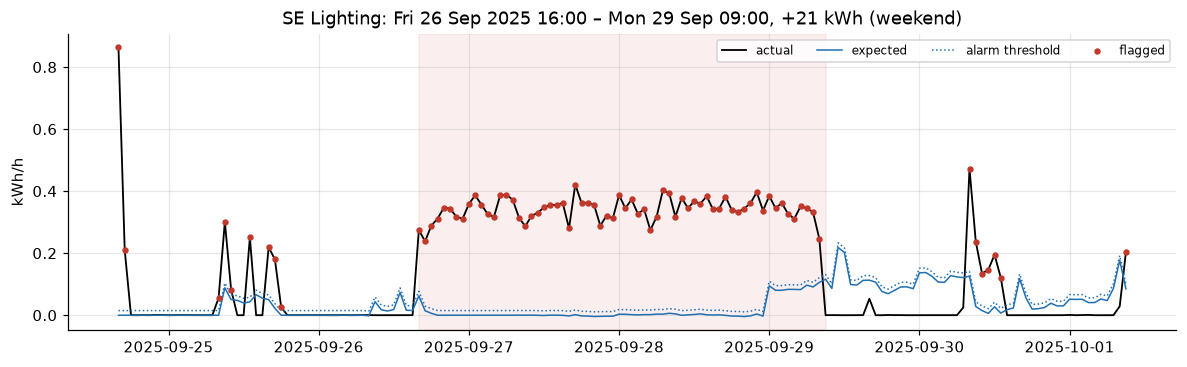

In [14]:
fig, ax = plt.subplots(figsize=(13, 3.5))
plot_event(ax, recent.iloc[0], days=2); ax.legend(ncol=4, fontsize=8)
save(fig, "05_recent_event"); plt.show()

**→ Finding:** In Aug–Oct 2025 the detector raises 37 events (≈ 4.6 per week over 9 circuits). The top one is a clear catch: **SE Lighting stayed on (~350 W) from Friday 26 Sep 16:00 until Monday 09:00 — 65 hours, +21 kWh, ≈ €3 and 5.5 kg CO₂ for one weekend**. Exactly the message a building manager can act on. Most other SE Lighting events, however, are weekdays 07:00–16:00 in August. In 2020-23 that light was almost never used, so in 2025 *normal* use looks unusual, and the calendar assumes the whole of August is closed. This is a **change in how the room is used**, not waste. Lesson: the model must be **retrained on recent data** before going live, and the dashboard needs a "this was normal" button so the manager's feedback becomes labels.

## 8. Conclusions and limitations

**What we built**

| Part | Result |
|---|---|
| Expected use | LightGBM_forecast per circuit (notebook 02), cross-fitted over the whole history |
| Signal 1 — events | robust threshold per circuit and hour type; k chosen so the manager gets ≈ 1 alarm per circuit per week; 98–100 % of injected loads found on 7 of 9 circuits, NW Plugs from ≈ 2 kW |
| Signal 2 — chronic waste | off-hours use above standby, per hour |
| Value | 2021: 7.2 MWh, €740–1,020, 1.9 t CO₂ · 2022: 6.0 MWh, €850–1,010, 1.6 t CO₂ |
| Biggest lever | heaters on the NW plug circuits at night, at weekends and in breaks (≈ 3–4 MWh/year); then the NW night light (≈ 1 MWh/year, check whether it is needed) |
| Dashboard inputs | `reports/anomaly_events.csv`, `offhours_waste_daily.csv`, `savings_summary.csv` |

**Limitations (to say in the presentation)**
* No ground truth: validated with synthetic anomalies and a manual check of the top events, not with confirmed waste.
* Standby = 10th percentile of night use; part of the off-hours use above it may be legitimate (late work, servers), so "potential" savings are an upper estimate of what is avoidable.
* Calendar assumptions (Christmas break until 6 Jan, whole of August closed) look wrong in places, and holiday events must be read with care.
* CO₂ factor (CNMC mix) and the all-in price are placeholders to be confirmed (KAN-134, KAN-23).
* The model learned 2020-23; 2025 shows changed use (SE Lighting). It should be retrained on recent data before going live.

**Next steps:** confirm calendar + CO₂ with the group, connect the CSV outputs to the Streamlit dashboard (PR #5), add a feedback button, retrain on 2025 data.